### Design a FIR Filter with Two Unwanted Frequencies
    sampling frequency = 200 Hz
    Duration = 3 seconds
    Useful frequencies = 4, 10, 15 Hz
    Unwanted frequencies = 40, 70 Hz
    Desired passband = 0-15 Hz
    Target passband error <= 5%

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

fs, duration = 200, 3
N = fs * duration
t = np.arange(N)/ fs

#Useful signal
clean = np.sin(2* np.pi * 4 * t) + np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 15 * t)

#Two unwnted components
noise40 = 1.5 * np.sin(2 * np.pi * 40 * t)
noise70 = 0.7 * np.sin(2 * np.pi * 70 * t)

#Measured signal
x = clean + noise40 + noise70

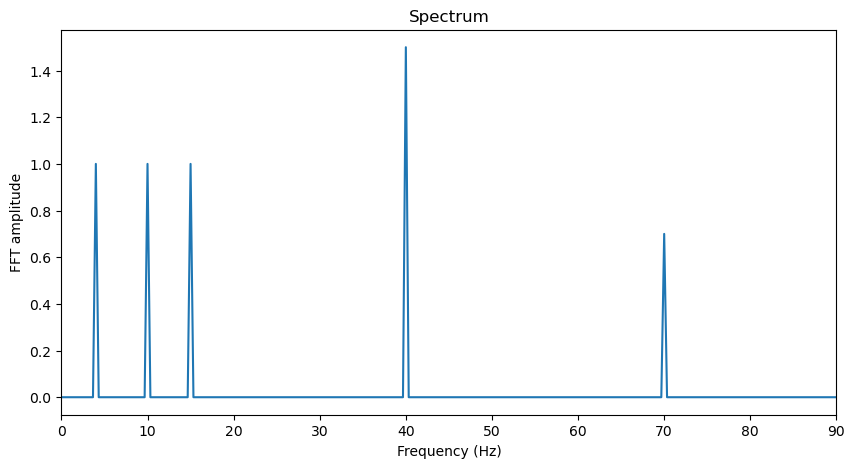

In [17]:
# FFT plot
freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_fft = np.abs(np.fft.rfft(x)) / N
amplitude_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fft)
plt.xlim(0, 90)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT amplitude")
plt.title("Spectrum")
plt.show()

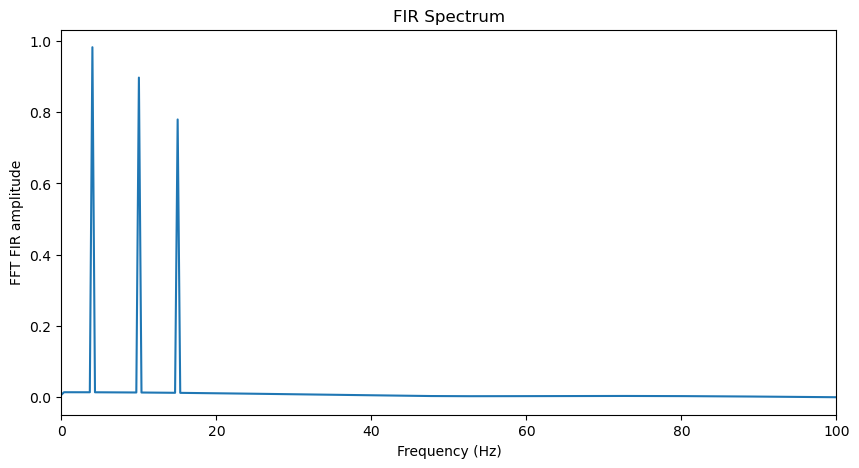

In [18]:
#Adding Zeros at Unwanted frequencies
theta40 = 2 * np.pi * 40 / fs
b1 = np.array([1, -2 * np.cos(theta40), 1])
theta70 = 2 * np.pi * 70 / fs
b2 = np.convolve(b1, [1, -2 * np.cos(theta70), 1])
b2 = b2 / sum(b2)

#Applying FIR filter to the noisy signal x
fir_out = lfilter(b2, [1], x)

fir_freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_fir_fft = np.abs(np.fft.rfft(fir_out)) / N
amplitude_fir_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(fir_freq_fft, amplitude_fir_fft)
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT FIR amplitude")
plt.title("FIR Spectrum")
plt.show()

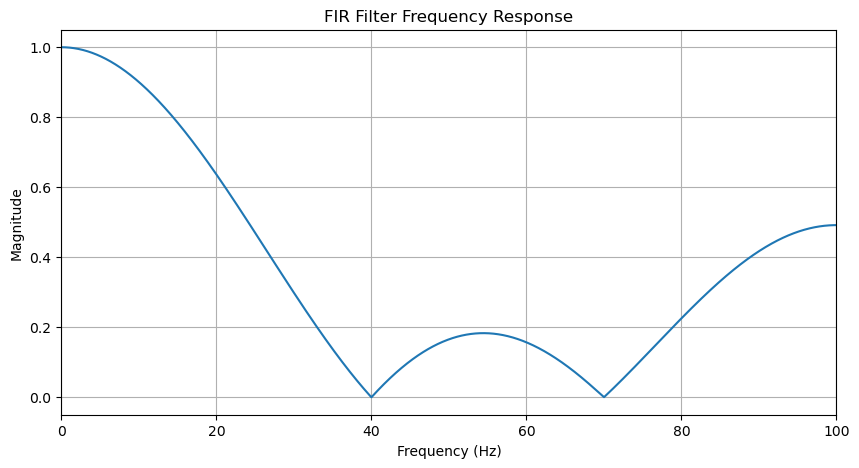

passband_error: %21.529241390172693


In [19]:
#Frequency response
f, H = freqz(b2, [1], worN = 2048, fs=fs)
magnitude = np.abs(H)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude)
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FIR Filter Frequency Response")
plt.grid(True)
plt.show()

passband = f <= 15
passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
print("passband_error:", f"%{passband_error}")

The filter successfully rejects 40 and 70 Hz, but it significantly attenuates part of the useful frequency range. So, this filter removes both unwanted frequencies but it does not satisfy the passband requirement.

# Manual IIR Filter Design

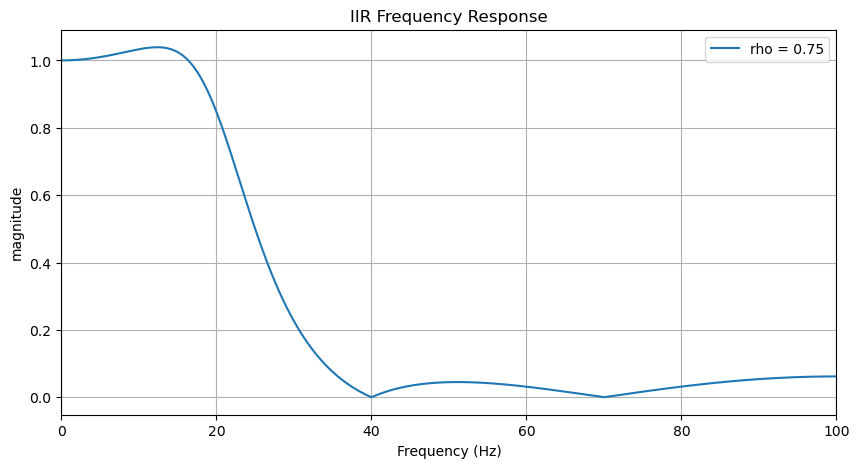

In [46]:
fb = 20
theta_b = 2 * np.pi * fb / fs
rho = 0.75
a = np.array([1, -2 * np.cos(theta_b) * rho, rho ** 2])
k = sum(a) / sum(b2)
b_iir = k * b2

f, H = freqz(b_iir, a, worN = 2048, fs=fs)
magnitude = np.abs(H)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude, label = "rho = 0.75")
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.title("IIR Frequency Response")
plt.grid(True)
plt.legend()
plt.show()

### Investigating different pole radii

rho = 0.6 : passband_error = %19.090377189225805
rho = 0.7 : passband_error = %7.3618956006413665
rho = 0.75 : passband_error = %3.914755721527219
rho = 0.85 : passband_error = %33.976978429200265
rho = 0.9 : passband_error = %55.186304905864716


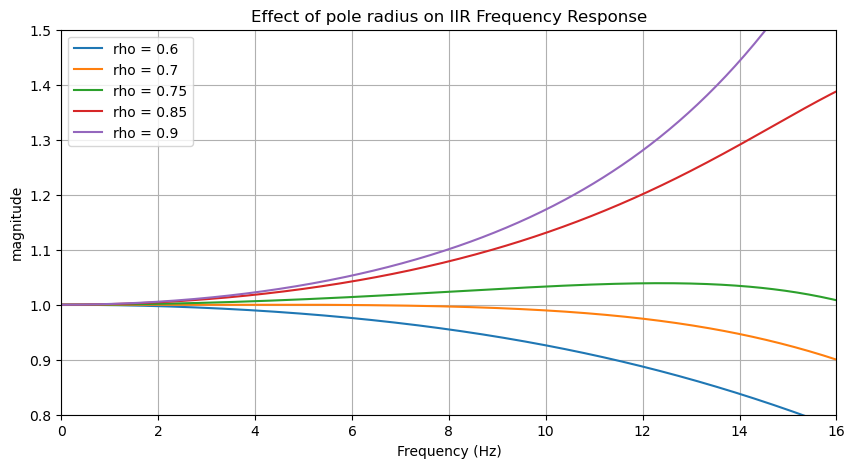

In [32]:
fb = 20
theta_b = 2 * np.pi * fb / fs
rhos = [0.60, 0.70, 0.75, 0.85, 0.90]
plt.figure(figsize=(10, 5))
for rho in rhos:
    a = np.array([1, -2 * np.cos(theta_b) * rho, rho ** 2])
    k = sum(a) / sum(b2)
    b_iir = k * b2

    f, H = freqz(b_iir, a, worN = 2048, fs=fs)
    magnitude = np.abs(H)
    plt.plot(f, magnitude, label = f"rho = {rho}")
    passband = f <= 15
    passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
    print(f"rho = {rho} : passband_error = %{passband_error}")
plt.xlim(0, 16)
plt.ylim(0.8, 1.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.title("Effect of pole radius on IIR Frequency Response")
plt.legend()
plt.grid(True)
plt.show()
    


rho = 0.75 is the best option because it produces the lowest passband_error

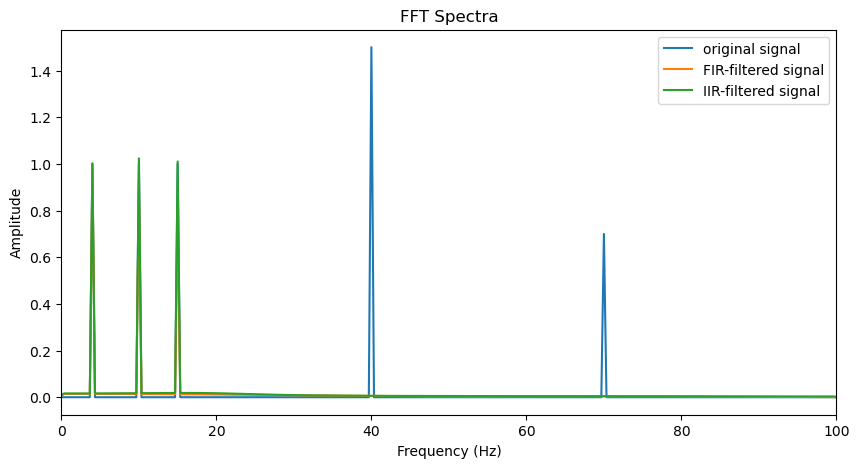

In [36]:
#Applying IIR filter to the noisy signal x
fb = 20
rho = 0.75
theta_b = 2 * np.pi * fb / fs
a = np.array([1, -2 * np.cos(theta_b) * rho, rho ** 2])
k = sum(a) / sum(b2)
b_iir = k * b2

iir_out = lfilter(b_iir, a, x)
iir_freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_iir_fft = np.abs(np.fft.rfft(iir_out)) / N
amplitude_iir_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fft, label = "original signal")
plt.plot(fir_freq_fft, amplitude_fir_fft, label = "FIR-filtered signal")
plt.plot(iir_freq_fft, amplitude_iir_fft, label = "IIR-filtered signal")
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT Spectra")
plt.legend()
plt.show()


    At 40 and 70 Hz, both filters successfully suppress the unwanted interference.
    At 10 and 15 Hz, the IIR filter preserves the useful amplitudes much more accurately than the FIR filter.

### FIR and IIR group delay

In [41]:
from scipy. signal import group_delay

#Useful frequencies
frequencies = [4, 10, 15]
f, delay_fir = group_delay((b2, [1]), w=frequencies, fs=fs)
_, delay_iir = group_delay((b_iir, a), w=frequencies, fs=fs)

#convert samples to milliseconds
delay_fir_ms = delay_fir / fs * 1000
delay_iir_ms = delay_iir / fs * 1000
print("FIR delay (ms):", delay_fir_ms)
print("IIR delay (ms):", delay_iir_ms)

FIR delay (ms): [10. 10. 10.]
IIR delay (ms): [11.74142697 14.65380923 19.74927102]


    The FIR has constant group delay because of its symmetric coefficients.
    The IIR delay changes with frequency. This means different frequency components may experience different delays, potentially affecting the shape of a signal containing several frequencies.

### Conclusion:
    The IIR filter preserves amplitudes more accurately but introduces frequency-dependent group delay.
    The FIR filter has a simpler delay characteristic, but its amplitude response does not meet our 5% requirement.
    
    Therefore, I would choose IIR filter here.